# Protein-ligand affinity: what the split protocol is actually measuring

Public DTI benchmarks (DAVIS, KIBA) are reported with a single number per model, and that
number moves more with the **split protocol** than with the model. This notebook reads the
outputs of `scripts/00` - `scripts/06` and walks through that claim with the leakage audit,
a five-model x five-protocol grid, split-conformal coverage, and an AutoDock Vina arm that
never saw the labels.

Reproduce end to end:

```
python scripts/00_fetch_data.py      # downloads + integrity checks (13 PASS)
python scripts/01_features.py        # ECFP4 counts + sequence composition
python scripts/02_splits.py          # 5 protocols + leakage audit
python scripts/03_models.py          # 5 models x 5 protocols x 3 seeds
python scripts/04_uncertainty.py     # split conformal on top of 03
python scripts/05_docking.py         # UniProt -> PDBe -> meeko -> Vina
python scripts/06_docking_analysis.py
python scripts/07_report.py
```

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display

# Find the repo root instead of trusting the kernel cwd. nbconvert starts the kernel with
# cwd = the notebook's own directory (notebook/), so a bare Path('scripts') would resolve to
# notebook/scripts and raise ModuleNotFoundError -- and a reader running the whole repo from
# an IDE may have cwd = repo root. Every path below is therefore anchored on ROOT, located
# by walking up until scripts/dti_core.py is found.
ROOT = Path.cwd()
while ROOT != ROOT.parent and not (ROOT / 'scripts' / 'dti_core.py').is_file():
    ROOT = ROOT.parent
assert (ROOT / 'scripts' / 'dti_core.py').is_file(), f'no repo root above {Path.cwd()}'
sys.path.insert(0, str(ROOT / 'scripts'))
from dti_core import evaluate, ci_harrell, ci_sklearn_like
pd.set_option('display.width', 200)
RES, PROC = ROOT / 'results', ROOT / 'data' / 'processed'

def show(fname):
    p = Path(fname)
    if not p.is_absolute():
        p = (ROOT / p).resolve()      # figure paths are written repo-root relative
    if p.exists():
        display(Image(filename=str(p)))
    else:
        print(f'[not built in this run: {fname}] -- run the stage that writes it; '
              f'this notebook does not display a stale or missing figure')
    return p.exists()

summary = json.loads((PROC/'data_summary.json').read_text(encoding='utf-8'))
summary['davis']

{'rows': 30056,
 'distinct_ligand_smiles': 68,
 'distinct_target_sequences': 379,
 'distinct_target_names': 442,
 'distinct_feature_pairs': 25772,
 'rows_sharing_features_with_another_row': 4284,
 'max_within_pair_pKd_spread': 2.6841,
 'fraction_at_censor_ceiling_pKd_5': 0.6964,
 'cross_source_rows_aligned': 30056,
 'cross_source_agree_within_0.02_pKd': 30056,
 'cross_source_mean_abs_delta_pKd': 0.0,
 'cross_source_max_abs_delta_pKd': 0.0,
 'cross_source_disagreeing_rows': 0,
 'feature_groups_with_any_disagreement': 0,
 'deposit_date_known_rows': 25194,
 'sum_of_five_published_files': 30056,
 'bad_smiles': 0,
 'caveat': 'target_name is recovered by sorting affinity values inside each (SMILES, sequence) group. 69.6% of DAVIS values sit on the censoring ceiling (pKd = 5.0), so within a group of sequence-identical targets the *label* is identical and the two are interchangeable for modelling; only the name attached to such a row is arbitrary. All modelling keys on the sequence (target_id)

## 1. Data integrity, before any modelling

Two things have to be true or every downstream number is meaningless: the row count has
to equal the sum of the five published DAVIS files, and the labels recovered from the
feature-only canonical files have to agree with the Kd table. `00_fetch_data.py` asserts
both; the numbers below are what it recorded.

Note `distinct_target_sequences` < `distinct_target_names`: 442 DAVIS target names collapse
onto 379 sequences, i.e. **the same protein features appear under two different names**, and
any split done on names leaks. This benchmark keys every split on `target_id` (sequence).

In [2]:
d = summary['davis']
k = summary['kiba']
pd.DataFrame([
    {'dataset': 'DAVIS', 'rows': d['rows'], 'ligands': d['distinct_ligand_smiles'],
     'target_names': d['distinct_target_names'], 'target_sequences': d['distinct_target_sequences'],
     'label': 'pKd', 'censored_share': d['fraction_at_censor_ceiling_pKd_5'],
     'cross_source_max_abs_delta': d['cross_source_max_abs_delta_pKd'],
     'files_sum_matches': d['sum_of_five_published_files']},
    {'dataset': 'KIBA', 'rows': k['rows'], 'ligands': k['distinct_ligand_smiles'],
     'target_names': k['distinct_target_keys'], 'target_sequences': k['distinct_target_sequences'],
     'label': 'KIBA score', 'censored_share': k['rows_at_floor']/k['rows'],
     'cross_source_max_abs_delta': None, 'files_sum_matches': k['published_split_counts']},
])

,dataset,rows,ligands,target_names,target_sequences,label,censored_share,cross_source_max_abs_delta,files_sum_matches
0,DAVIS,30056,68,442,379,pKd,0.696400,0.0,30056
1,KIBA,118254,2068,229,229,KIBA score,0.000008,NaN,"{'train': 94603, 'test': 23651}"


## 2. The leakage audit: five protocols, five different questions

`random` is not a scaffold split, `cold_drug` is not scaffold-disjoint, and `temporal`
throws away most of the data. The columns that matter:

* `test_pairs_with_near_duplicate_ligand_ge0.7` - share of test rows whose ligand has an
  ECFP4 Tanimoto twin >= 0.7 in train (a memorised near-duplicate)
* `test_scaffold_present_in_train` - share of test rows whose Murcko scaffold is in train
* `test_targets_absent_from_train` - share of test targets never seen in train

In [3]:
au = pd.read_csv(RES/'leakage_audit.csv')
cols = ['dataset','protocol','n_train','n_valid','n_test','excluded_rows','test_ligands',
        'test_ligands_absent_from_train','test_targets_absent_from_train',
        'test_scaffold_present_in_train','test_pairs_with_near_duplicate_ligand_ge0.7',
        'test_pairs_with_near_duplicate_ligand_ge0.95','target_max_dpc_cosine_to_train_target_mean',
        'temporal_cutoff']
au[[c for c in cols if c in au.columns]]

,dataset,protocol,n_train,n_valid,n_test,excluded_rows,test_ligands,test_ligands_absent_from_train,test_targets_absent_from_train,test_scaffold_present_in_train,test_pairs_with_near_duplicate_ligand_ge0.7,test_pairs_with_near_duplicate_ligand_ge0.95,target_max_dpc_cosine_to_train_target_mean,temporal_cutoff
0,davis,random,21039,3006,6011,0,68,0.0,0.0,1.0000,0.0130,0.0000,1.0000,NaN
1,davis,scaffold,21658,2652,5746,0,13,1.0,0.0,0.0000,0.0000,0.0000,1.0000,NaN
2,davis,cold_drug,21658,2652,5746,0,13,1.0,0.0,0.0000,0.0000,0.0000,1.0000,NaN
3,davis,cold_target,21080,2992,5984,0,68,0.0,1.0,1.0000,0.0147,0.0000,0.8461,NaN
4,davis,temporal,17238,2652,5304,4862,12,1.0,0.0,0.0000,0.0000,0.0000,1.0000,2014-01-01
5,kiba,random,82778,11825,23651,0,2017,0.0,0.0,1.0000,0.3498,0.0052,1.0000,NaN
6,kiba,scaffold,82778,11825,23651,0,296,1.0,0.0,0.0000,0.1098,0.0000,1.0000,NaN
7,kiba,cold_drug,82778,11825,23651,0,166,1.0,0.0,0.4879,0.2621,0.0000,1.0000,NaN
8,kiba,cold_target,82789,11823,23642,0,2067,0.0,1.0,1.0000,0.3541,0.0074,0.8129,NaN
9,kiba,temporal,30297,5376,9018,73563,116,1.0,0.0,0.0937,0.0181,0.0000,1.0000,2013-01-01


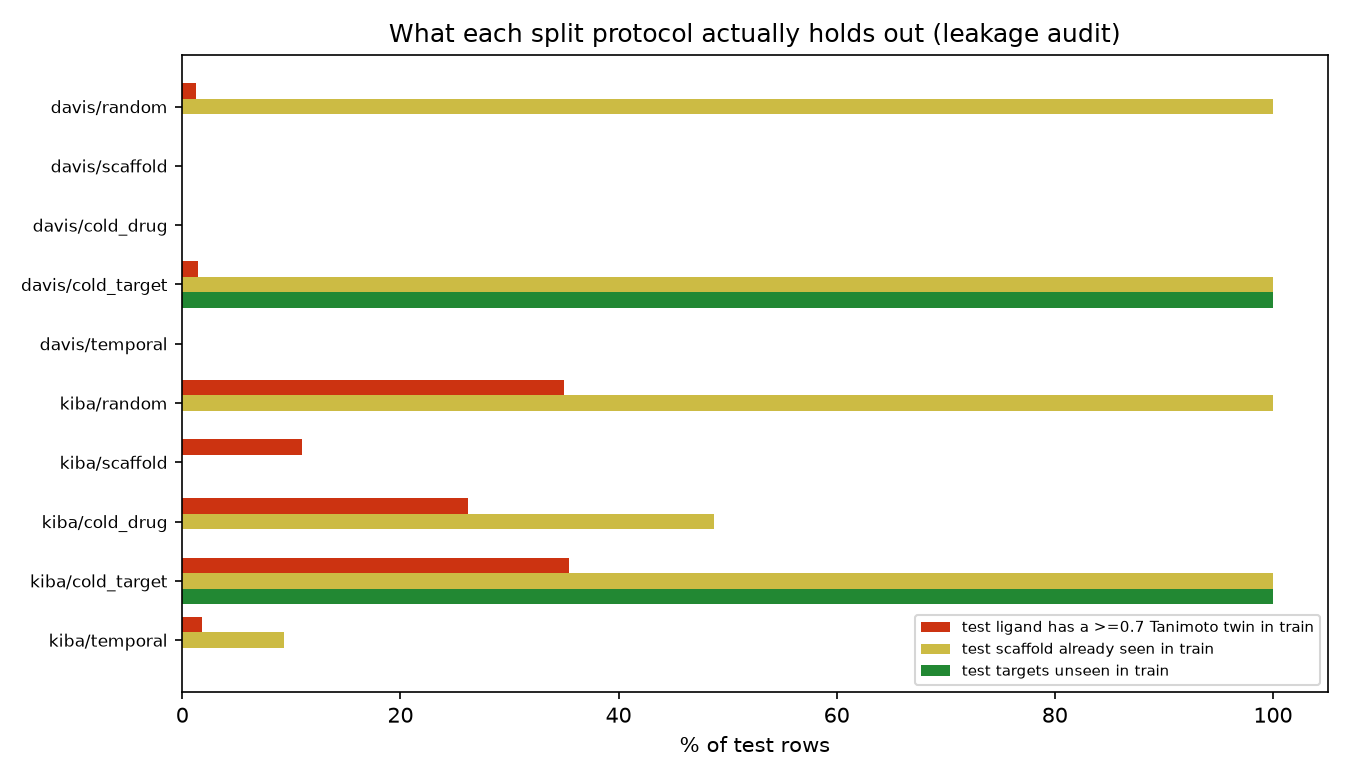

True

In [4]:
from IPython.display import Image, display
show('results/figures/fig1_leakage_by_protocol.png')

Read the KIBA rows: under `random`, **35%** of the test pairs have a near-duplicate ligand
already in the training set; under a real scaffold split that drops to 11%. So a KIBA
"random split" number is partly a similarity lookup. And `cold_drug` is NOT a scaffold
split -- about half of its held-out drugs keep a scaffold that training already saw.

For DAVIS the two cuts have the **same block sizes** (21,658 / 2,652 / 5,746) and both come
out scaffold-disjoint (`test_scaffold_present_in_train` = 0), because 68 inhibitors only
span 13 Murcko scaffolds, so holding drugs out by entity and holding them out by scaffold
converge on the same *shape* of cut. They are **not the same cut**: only 3 of the 13
held-out ligands overlap (`02_splits.py` assigns them independently). KIBA, with 2,068
drugs and many more scaffolds, shows the difference clearly -- its `cold_drug` keeps
48.8 % of test rows on a scaffold that training already saw.

The `temporal` rows also report `excluded_rows`: undated assays cannot be placed in time,
so they are dropped and counted instead of being silently kept.

## 3. Five models across five protocols

Models are deliberately classical (train-mean null, ridge, XGBoost, random forest, a
DeepDTA-style MLP): the question is what the protocol measures, not who has the largest
network. The table below averages the 3 seeds of each learned model (the three null
baselines are deterministic, so they have a single row); features are ECFP4 count bits plus
amino-acid / dipeptide composition, standardised with training statistics only.

In [5]:
m = pd.read_csv(RES/'metrics.csv')
m.groupby(['dataset','protocol','model'])[['rmse','ci_harrell','ci_sklearn_like','pearson_r']].mean().round(4)

rmse  ci_harrell  ci_sklearn_like  pearson_r
dataset protocol  model                                                            
davis   cold_drug mean               0.9173      0.5000           0.5000        NaN
                  mean_ligand_train  0.9173      0.5000           0.5000        NaN
                  mean_target_train  0.8637      0.6683           0.5986     0.3380
                  mlp                1.4814      0.6639           0.5960     0.3851
                  randomforest       0.7877      0.6889           0.6106     0.5122
...                                     ...         ...              ...        ...
kiba    temporal  mean_target_train  0.7832      0.6526           0.6440     0.2922
                  mlp                1.7832      0.5385           0.5363     0.1207
                  randomforest       0.7244      0.6884           0.6777     0.4706
                  ridge              0.9798      0.5645           0.5609     0.2125
                  xgboost            0.7583      0.6622           0.6530     0.4185

[70 rows x 4 columns]

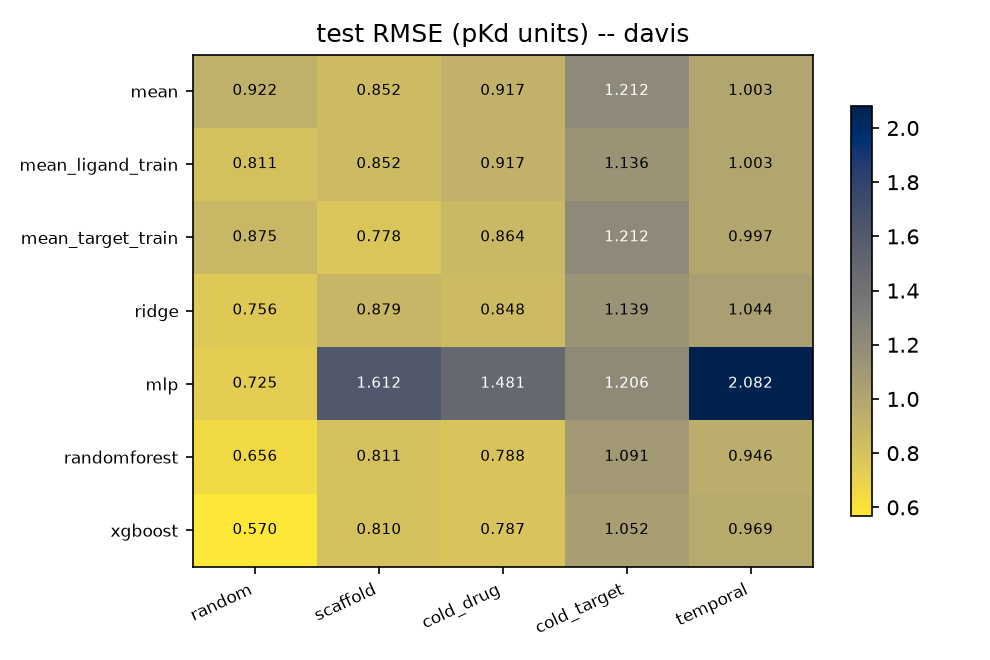

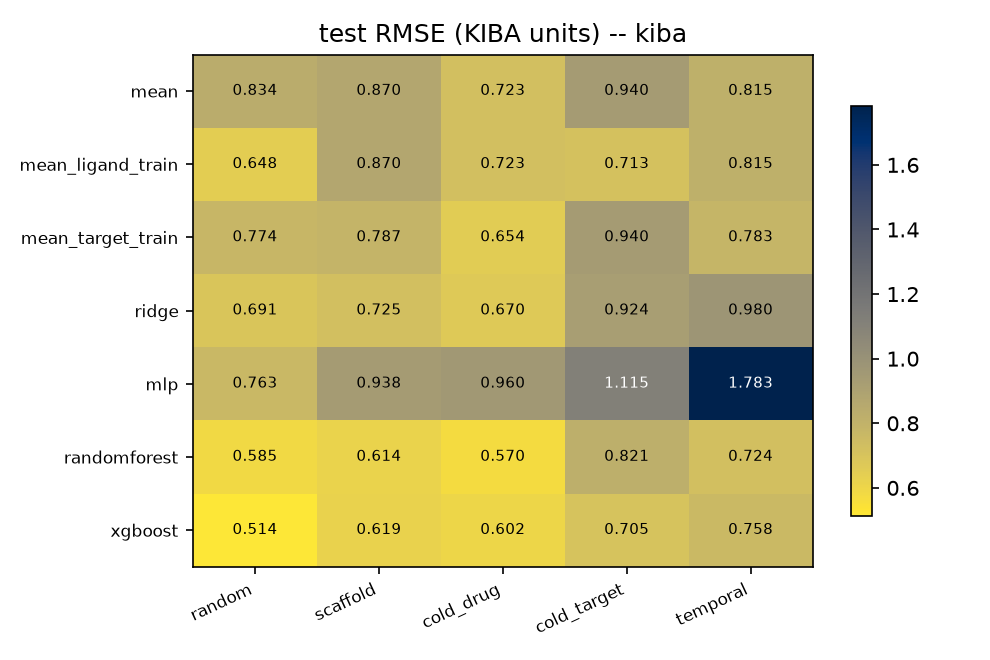

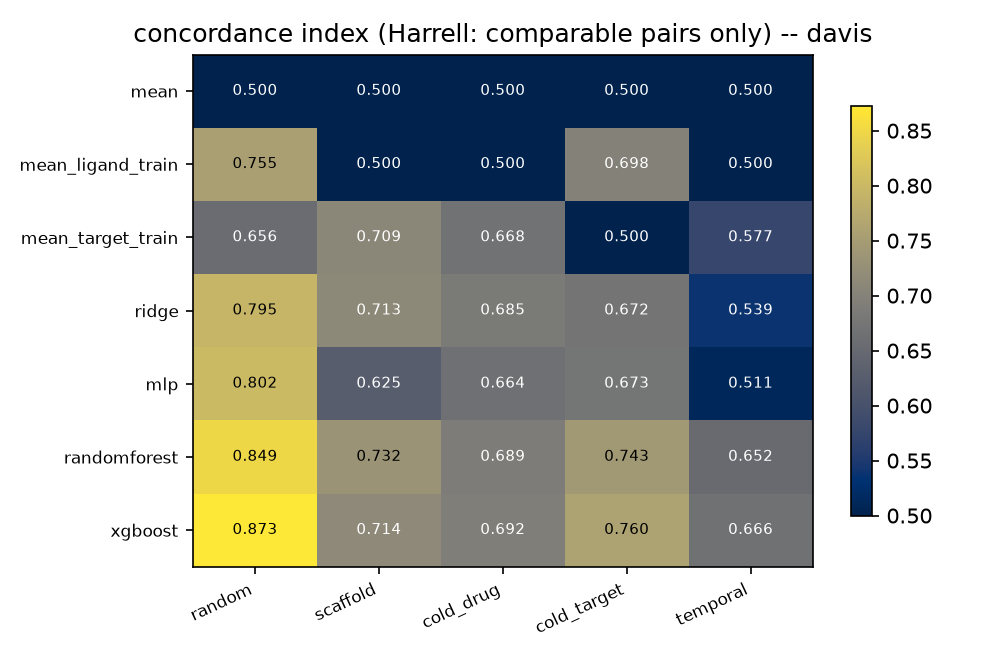

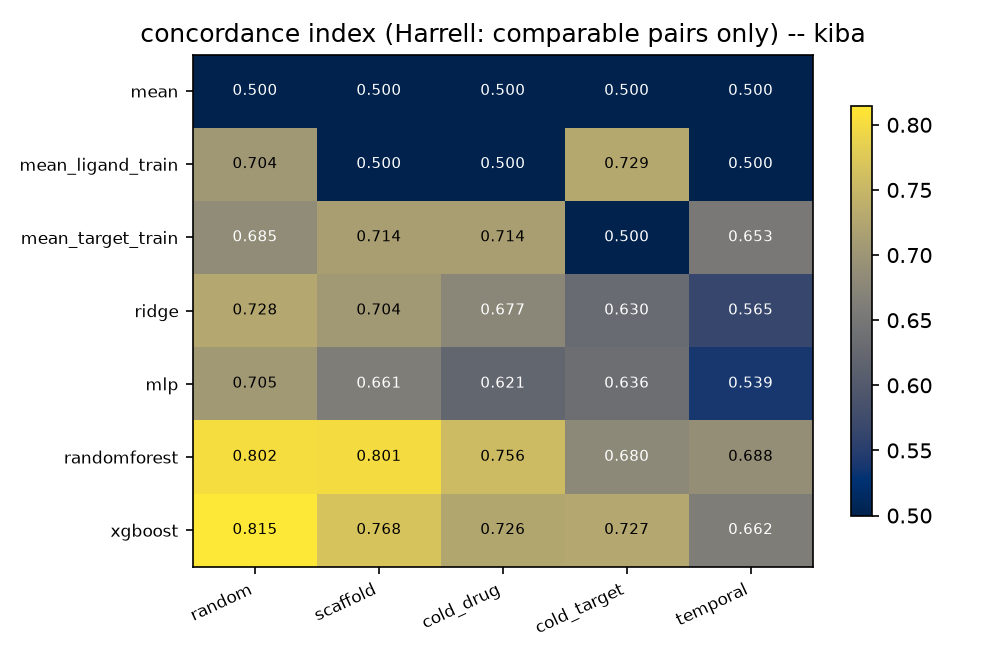

True

In [6]:
show('results/figures/fig2a_davis_rmse.png')
show('results/figures/fig2b_kiba_rmse.png')
show('results/figures/fig2c_davis_ci.png')
show('results/figures/fig2d_kiba_ci.png')

### The reporting hazard nobody states

`ci_harrell` — the convention the DTI literature actually uses — restricts the denominator
to *comparable* pairs: a pair whose two labels are equal is dropped, and a pair whose
predictions are equal gets 0.5 credit. `ci_sklearn_like` keeps every pair and gives a
label-tied pair 0.5 credit instead. DAVIS puts ~two-thirds of its *rows* on the censoring
ceiling (pKd 5.0), and that turns into **36.4–48.7 % of the label *pairs* inside a test block
being exact ties** (KIBA: 5.1–6.7 %) — close to half, not most, but enough that the second
caliber is dragged toward 0.5 by construction. Both are in `results/metrics.csv` because the
two disagree by up to 0.18 on the same predictions, and picking one silently is how
benchmarks get inflated.

Three different quantities all get called "ties", so the next cell prints them separately:
the pair share (the `ci_harrell` denominator loss), the row share on the modal label (the
censoring), and `1 − distinct/rows` (plain redundancy, which is ~93–98 % on both datasets and
says nothing about concordance at all).

In [7]:
pd.read_csv(RES/'label_tie_measures.csv')

,dataset,protocol,n_test,n_distinct_labels,pct_label_pairs_tied,pct_rows_on_modal_label,pct_redundancy_metrics_csv
0,davis,random,6011,371,48.65,69.72,93.83
1,davis,scaffold,5746,351,47.33,68.76,93.89
2,davis,cold_drug,5746,364,41.44,64.32,93.67
3,davis,cold_target,5984,432,36.40,60.28,92.78
4,davis,temporal,5304,378,42.66,65.27,92.87
5,kiba,random,23651,1025,5.61,12.43,95.67
6,kiba,scaffold,23651,696,6.18,13.61,97.06
7,kiba,cold_drug,23651,602,6.66,13.77,97.45
8,kiba,cold_target,23642,1412,5.05,15.19,94.03
9,kiba,temporal,9018,333,5.68,11.78,96.31


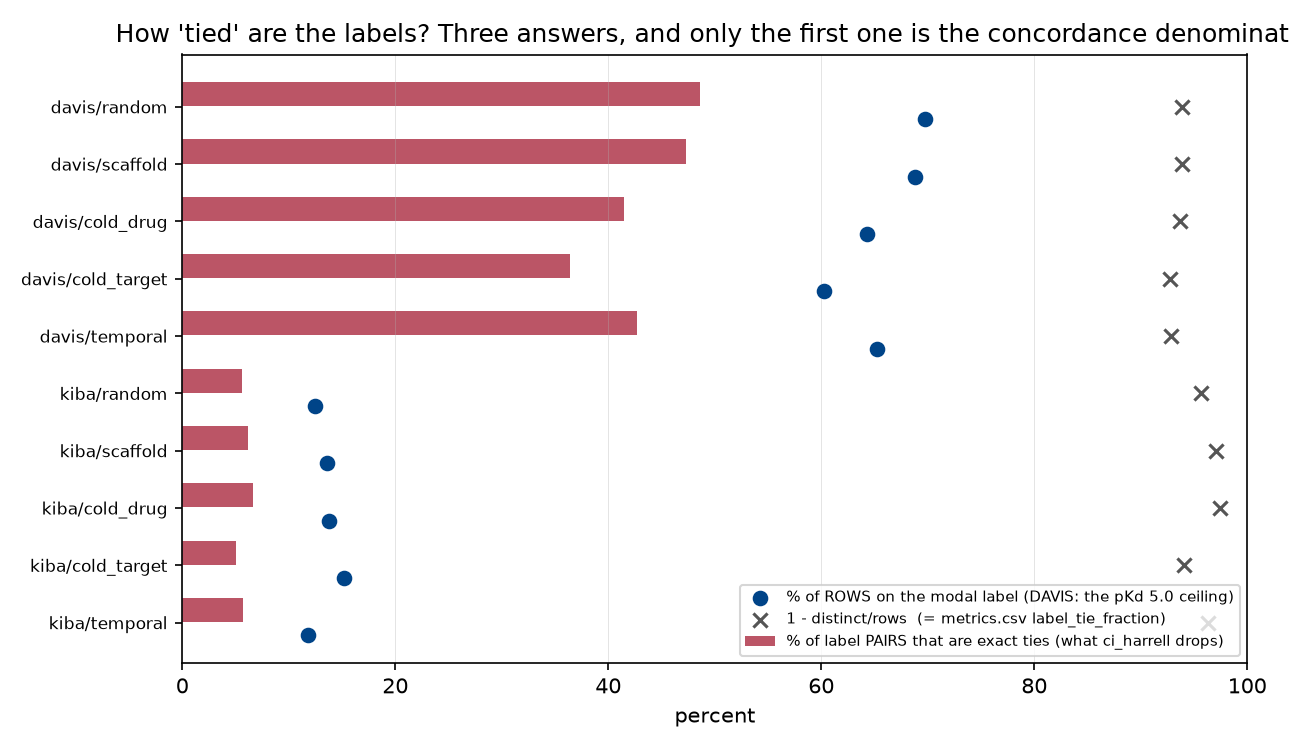

True

In [8]:
show('results/figures/fig4_label_ties.png')

In [9]:
m2 = m[m.dataset=='davis']
print('CI, comparable pairs only (Harrell / DTI convention), davis')
display(pd.pivot_table(m2, index='model', columns='protocol',
                       values='ci_harrell').round(3).dropna(how='all'))
print('CI, every pair counted and label ties given 0.5 (sklearn-like), davis')
display(pd.pivot_table(m2, index='model', columns='protocol',
                       values='ci_sklearn_like').round(3).dropna(how='all'))

CI, comparable pairs only (Harrell / DTI convention), davis


protocol,cold_drug,cold_target,random,scaffold,temporal
model,,,,,
mean,0.500,0.500,0.500,0.500,0.500
mean_ligand_train,0.500,0.698,0.755,0.500,0.500
mean_target_train,0.668,0.500,0.656,0.709,0.577
mlp,0.664,0.673,0.802,0.625,0.511
randomforest,0.689,0.743,0.849,0.732,0.652
ridge,0.685,0.672,0.795,0.713,0.539
xgboost,0.692,0.760,0.873,0.714,0.666


CI, every pair counted and label ties given 0.5 (sklearn-like), davis


protocol,cold_drug,cold_target,random,scaffold,temporal
model,,,,,
mean,0.500,0.500,0.500,0.500,0.500
mean_ligand_train,0.500,0.626,0.631,0.500,0.500
mean_target_train,0.599,0.500,0.580,0.610,0.544
mlp,0.596,0.610,0.655,0.566,0.506
randomforest,0.611,0.654,0.679,0.622,0.587
ridge,0.608,0.609,0.651,0.612,0.522
xgboost,0.613,0.665,0.691,0.613,0.595


### The negative result, kept in

Under the forward-in-time DAVIS protocol the linear model is **worse than predicting the
training mean** (`pearson_r` collapses to ~0). That is written into `results/metrics.csv`
and into the README rather than dropped: assay batches drift, and a protocol that puts the
future in the test set measures that drift.

In [10]:
tm = m[(m.dataset=='davis') & (m.protocol=='temporal')][['model','seed','rmse','pearson_r','ci_harrell']]
tm.sort_values('rmse')

,model,seed,rmse,pearson_r,ci_harrell
69,randomforest,0,0.941253,0.297316,0.658432
70,randomforest,1,0.942483,0.292129,0.655838
71,randomforest,2,0.953781,0.259889,0.641249
66,xgboost,0,0.961840,0.301350,0.668211
67,xgboost,1,0.964489,0.308244,0.674164
68,xgboost,2,0.981199,0.268589,0.656380
61,mean_target_train,0,0.996640,0.171956,0.577182
60,mean_ligand_train,0,1.002955,NaN,0.500000
62,mean,0,1.002955,NaN,0.500000
64,ridge,1,1.044166,0.054513,0.538704


## 4. How wrong can a single prediction be? (split conformal)

`04_uncertainty.py` uses each protocol's validation block as a calibration set, computes
conformal quantiles, and then MEASURES how much of the test block the interval actually
covers. Constant width, and a normalised variant whose width follows a sigma-hat model.

In [11]:
cf = pd.read_csv(RES/'uncertainty/conformal.csv')
cf[[c for c in ['dataset','protocol','model','method','n_cal','rmse','rmse_matches_03','q90',
                'width90','cov50','cov80','cov90','coverage_error','corr_absres_sigma'] if c in cf.columns]]

,dataset,protocol,model,method,n_cal,rmse,rmse_matches_03,q90,width90,cov50,cov80,cov90,coverage_error,corr_absres_sigma
0,davis,random,ridge,conformal,3006,0.7561,True,1.0834,2.1668,0.5129,0.8005,0.8959,0.0062,NaN
1,davis,random,ridge,conformal_norm,1503,0.7561,True,3.0787,3.0524,0.5199,0.7929,0.8924,0.0111,0.3985
2,davis,random,xgboost,conformal,3006,0.5686,True,0.8690,1.7379,0.5151,0.8025,0.8950,0.0063,NaN
3,davis,random,xgboost,conformal_norm,1503,0.5686,True,3.4973,2.4391,0.5209,0.8237,0.9200,0.0170,0.3246
4,davis,scaffold,ridge,conformal,2652,0.8786,True,1.3738,2.7476,0.7001,0.8232,0.8839,0.0807,NaN
5,davis,scaffold,ridge,conformal_norm,1326,0.8786,True,1.8475,2.6485,0.6664,0.7628,0.8637,0.0637,0.2295
6,davis,scaffold,xgboost,conformal,2652,0.8199,True,1.1968,2.3935,0.5115,0.7471,0.8811,0.0205,NaN
7,davis,scaffold,xgboost,conformal_norm,1326,0.8199,True,2.8643,2.7621,0.5052,0.7123,0.7973,0.0669,0.2629
8,davis,cold_drug,ridge,conformal,2652,0.8479,True,1.2143,2.4286,0.3663,0.7052,0.8777,0.0978,NaN
9,davis,cold_drug,ridge,conformal_norm,1326,0.8479,True,3.8262,3.8090,0.4043,0.7358,0.8716,0.0683,0.2233


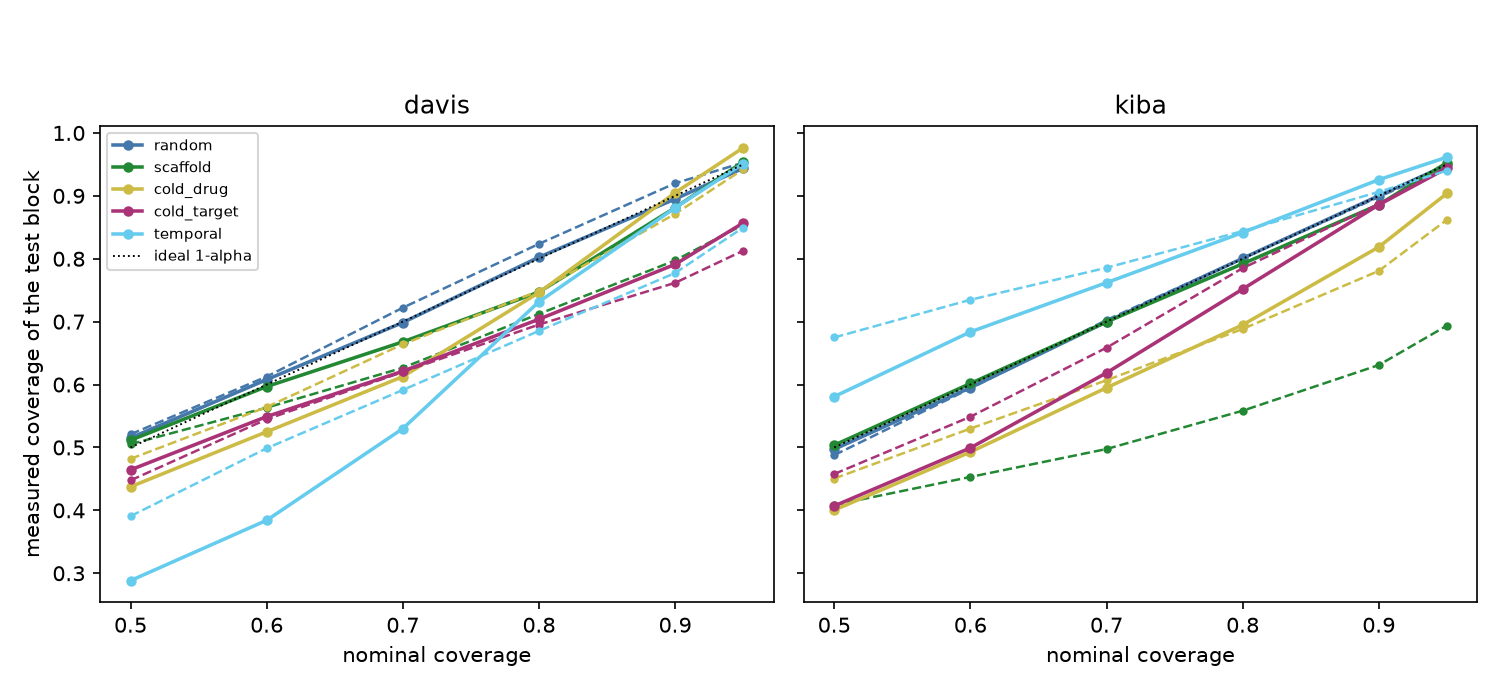

True

In [12]:
show('results/figures/fig5_conformal_coverage.png')

## 5. A physics arm that never saw the labels (AutoDock Vina)

For each panel kinase: gene -> UniProt -> PDBe SIFTS `best_structures` (X-ray, <= 2.6 A,
coverage >= 0.35) -> RCSB coordinates -> keep the assayed chain, check its sequence
against the DAVIS sequence with local alignment -> box from the co-crystal drug-like
ligand -> meeko (gasteiger) -> `vina.exe`. Compounds come from RDKit ETKDG+MMFF of the
DAVIS SMILES, so the pose is not a crystal pose and the receptor is rigid.

The score is *not* a affinity in pKd units, so it is compared as a ranker (concordance)
and through a two-parameter train-fitted linear map, on exactly the rows the trained
models predict.

In [13]:
panel = pd.read_csv(RES/'docking/target_panel.csv')
panel[['target_id','gene','uniprot_acc','pdb_id','chain','resolution','pdbe_coverage',
       'identity_vs_davis','identity_vs_uniprot','cocrystal_ligand','cocrystal_heavy',
       'meeko_bad_residues_dropped']]

,target_id,gene,uniprot_acc,pdb_id,chain,resolution,pdbe_coverage,identity_vs_davis,identity_vs_uniprot,cocrystal_ligand,cocrystal_heavy,meeko_bad_residues_dropped
0,T0004,CDC2L1,P21127,7ukz,A,2.60,0.389,0.9767,0.9767,NK3,28,47
1,T0006,ERK2,P28482,8aoj,A,1.12,1.000,0.9798,0.9798,N8L,21,0
2,T0007,ERK1,P27361,4qtb,A,1.40,1.000,1.0000,1.0000,38Z,44,0
3,T0012,ADCK3,Q8NI60,7udq,A,1.90,0.606,0.9560,0.9560,MVS,25,0
4,T0013,BRAF,P15056,8c7x,A,1.65,0.363,0.9487,0.9487,TXV,34,2
5,T0015,MKK7,O14733,6yz4,A,1.70,0.730,0.9539,0.9539,1E8,33,8


In [14]:
pairs = pd.read_csv(RES/'docking/pairs.csv')
pairs.describe().loc[['count','mean','std','min','25%','50%','75%','max'],['pkd','vina_best','vina_seconds']]

,pkd,vina_best,vina_seconds
count,140.000000,140.000000,140.000000
mean,5.208015,-8.932879,70.400714
std,0.698188,1.279841,67.518583
min,5.000000,-12.016000,8.700000
25%,5.000000,-9.632000,27.425000
50%,5.000000,-8.931000,50.500000
75%,5.000000,-8.085750,83.000000
max,9.744727,-5.935000,353.200000


In [15]:
comp = pd.read_csv(RES/'docking/comparison.csv')
comp.head(40)

,comparison,scope,gene,subset,model,n,n_fit,n_comparable_pairs,n_tied_label_pairs,slope,...,rmse_vina,ci_vina,ci_sk_vina,r_vina,delta_ci_favours,label_tie_fraction,note,mean_onsite_kcal,mean_shifted_kcal,ci_harrell_onsite
0,vina_ranking,all_docked_pairs,NaN,-,NaN,140,NaN,2590.0,7140.0,NaN,...,NaN,NaN,NaN,NaN,NaN,0.850,NaN,NaN,NaN,NaN
1,vina_ranking,target:T0004,CDC2L1,-,NaN,20,NaN,70.0,120.0,NaN,...,NaN,NaN,NaN,NaN,NaN,0.750,NaN,NaN,NaN,NaN
2,vina_ranking,target:T0006,ERK2,-,NaN,20,NaN,19.0,171.0,NaN,...,NaN,NaN,NaN,NaN,NaN,0.900,NaN,NaN,NaN,NaN
3,vina_ranking,target:T0007,ERK1,-,NaN,20,NaN,19.0,171.0,NaN,...,NaN,NaN,NaN,NaN,NaN,0.900,NaN,NaN,NaN,NaN
4,vina_ranking,target:T0012,ADCK3,-,NaN,20,NaN,19.0,171.0,NaN,...,NaN,NaN,NaN,NaN,NaN,0.900,NaN,NaN,NaN,NaN
5,vina_ranking,target:T0013,BRAF,-,NaN,40,NaN,374.0,406.0,NaN,...,NaN,NaN,NaN,NaN,NaN,0.700,NaN,NaN,NaN,NaN
6,vina_ranking,target:T0015,MKK7,-,NaN,20,NaN,37.0,153.0,NaN,...,NaN,NaN,NaN,NaN,NaN,0.850,NaN,NaN,NaN,NaN
7,vina_regression,pooled,NaN,random,NaN,26,105.0,94.0,NaN,0.0676,...,NaN,NaN,NaN,NaN,NaN,0.808,NaN,NaN,NaN,NaN
8,model_vs_vina,pooled,NaN,random,mean_ligand_train,26,NaN,94.0,NaN,NaN,...,1.0193,0.6383,0.5400,0.1511,model,NaN,NaN,NaN,NaN,NaN
9,model_vs_vina,pooled,NaN,random,mean,26,NaN,94.0,NaN,NaN,...,1.0193,0.6383,0.5400,0.1511,vina,NaN,NaN,NaN,NaN,NaN


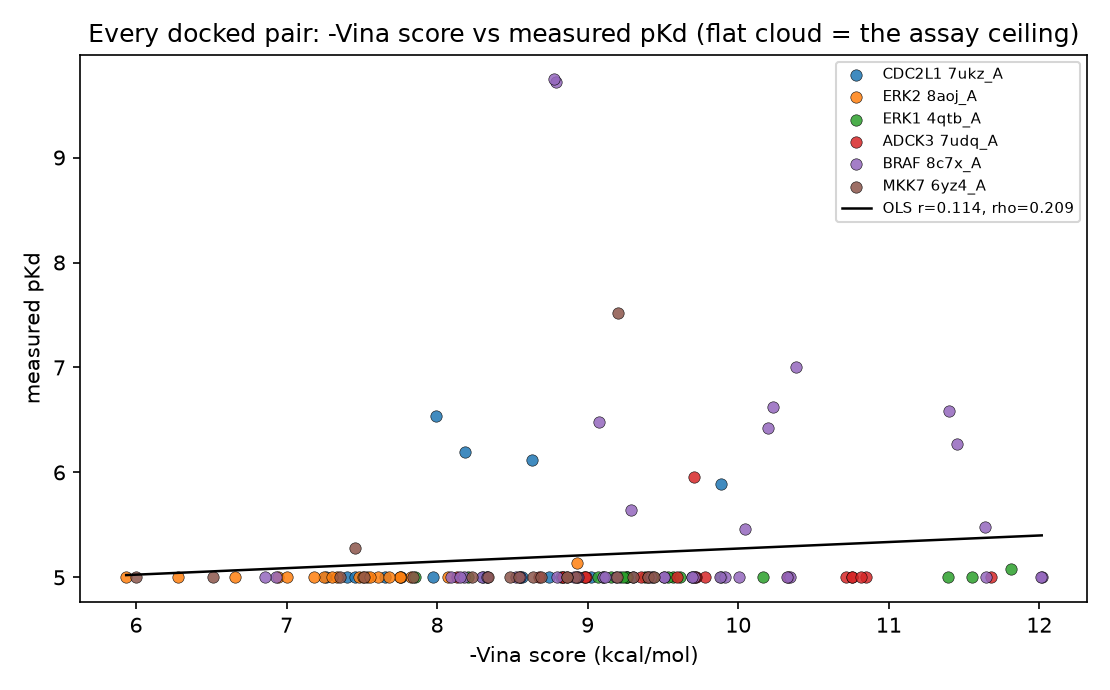

True

In [16]:
show('results/figures/fig6_docking_vs_pkd.png')

### Specificity control

Re-docking the same compounds into a box translated +30 A into the solvent should destroy
the signal. `results/docking/decoy_control.csv` holds that measurement, which is what
separates "the box is right" from "the score is noise".

In [17]:
import os
pd.read_csv(RES/'docking/decoy_control.csv') if os.path.exists(RES/'docking/decoy_control.csv') else 'not run'

,pair_id,target_id,ligand_id,pkd,vina_shifted,vina_rc
0,888,T0004,L00078,5.000000,-5.050,0
1,4866,T0004,L00349,5.000000,-6.270,0
2,7518,T0004,L00489,5.000000,-4.732,0
3,9286,T0004,L00585,5.000000,-7.133,0
4,11496,T0004,L00727,5.000000,-6.526,0
5,12822,T0004,L00772,5.000000,-7.072,0
6,15032,T0004,L00836,5.000000,-6.517,0
7,19010,T0004,L01091,6.537602,-6.512,0
8,21220,T0004,L01163,5.000000,-7.791,0
9,24756,T0004,L01320,5.000000,-6.537,0


## 6. What this repo does and does not claim

**Claims**
- Every protocol/label/feature decision is asserted in code with printed PASS/FAIL checks.
- Metrics are reported for 4 learned models x 5 protocols x 3 seeds on each of DAVIS and
  KIBA (120 fitted runs), plus 3 deterministic null baselines per protocol x dataset, both
  CI calibers, with the null floors.
- Conformal coverage is measured per protocol, not assumed.
- The docking arm is scored on identical rows to the ML arm, with a negative control.

**Does not claim**
- No deep DTI architecture is proposed; the models are baselines by design.
- DAVIS is 68 compounds against 442 target names (379 distinct sequences) - far too small
  to support a generalisation claim about drug affinity, and 69.6% of its labels are censored.
- The docking panel is a handful of kinases with a single rigid structure each; its
  correlation with assay affinity is an observation about this subset, not about docking.
- KIBA's temporal protocol keeps only ~38% of rows (deposits are known for 0.378 of them),
  so the drift result there is weaker evidence than the DAVIS one.

In [18]:
json.loads((RES/'summary.json').read_text(encoding='utf-8'))

{'generated_by': 'scripts/07_report.py',
 'figures_built': ['fig1_leakage_by_protocol.png',
  'fig2a_davis_rmse.png',
  'fig2b_kiba_rmse.png',
  'fig2c_davis_ci.png',
  'fig2d_kiba_ci.png',
  'fig3_rmse_vs_ci.png',
  'fig4_label_ties.png',
  'fig5_conformal_coverage.png',
  'fig6_docking_vs_pkd.png'],
 'best_model_per_protocol': {'davis/cold_drug': {'model': 'xgboost',
   'rmse': 0.7872,
   'ci_harrell': 0.6924},
  'davis/cold_target': {'model': 'xgboost',
   'rmse': 1.052,
   'ci_harrell': 0.7595},
  'davis/random': {'model': 'xgboost', 'rmse': 0.5697, 'ci_harrell': 0.8727},
  'davis/scaffold': {'model': 'xgboost', 'rmse': 0.8104, 'ci_harrell': 0.714},
  'davis/temporal': {'model': 'randomforest',
   'rmse': 0.9458,
   'ci_harrell': 0.6518},
  'kiba/cold_drug': {'model': 'randomforest',
   'rmse': 0.5697,
   'ci_harrell': 0.7564},
  'kiba/cold_target': {'model': 'xgboost',
   'rmse': 0.7052,
   'ci_harrell': 0.7274},
  'kiba/random': {'model': 'xgboost', 'rmse': 0.5143, 'ci_harrell': 